# GVH Diagonal Cubic — CHH-02 : Conservation et agrégation (FAST)

**Suite directe du checkpoint CHH-01.** Statut : *audit complémentaire, non canonique* ; aucun résultat ne requalifie `S_cand` en théorie physique validée.

**Question testée :** quelles grandeurs d'un ensemble de **sous-cubes hétérodynamiques** peuvent être composées exactement, et quelle erreur produit une réduction qui ne conserve qu'une description monopolaire ?

**Plan immuable :** Niveau 1 — proposition GVH ; Niveau 2 — mécanique et conservation établies ; Niveau 3 — test numérique minimal reproductible ; Niveau 4 — verdict scientifique.

**Conditions :** 4 corps fictifs identiques à CHH-01 (étiquettes Soleil/Terre/Lune/Jupiter **analogiques uniquement**), masses/positions/vitesses/unités synthétiques adimensionnées, couplage newtonien illustratif `κ=0.06` **prescrit**, aucun transfert vers les unités SI. Un modèle mécanique fermé et un réseau de transport ouvert sont **deux expériences séparées**, non une théorie matière complète. Aucune image ou raie ALMA n'est analysée.

## Niveau 1 — Architecture CHH et provenance

Nous conservons le sens de CHH-01 :

\[
C_i=(\mathcal X_i,x_i,\mathcal O_i,\mathcal Q_i,\mathcal I_i),\qquad
C_{\rm eff}=\mathcal A_\ell(\{C_i\},\{I_{ij}\}).
\]

L'agrégation **exacte du registre** n'est pas équivalente à une *équation d'évolution fermée* du cube effectif. Un registre peut additionner des masses et des énergies sans fournir les variables suffisantes pour prédire le futur.

**Stratégie :** (a) calculer un registre complet des 15 partitions en groupes de quatre sous-cubes, (b) mesurer la perte énergétique quand les degrés relatifs et les interactions internes sont cachés, (c) tester un bilan de flux sur un réseau ouvert, (d) comparer le champ extérieur exact aux réductions monopôle et quadrupôle, (e) vérifier les invariants d'une dynamique mécanique connue.

In [1]:
import json, math, hashlib
from itertools import combinations
from pathlib import Path
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

NAME = 'GVH_CHH_02_Conservation_and_Aggregation_FAST'
RESULT_FILE = NAME + "_results.json"
UPSTREAM = {'GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_EXECUTED.ipynb': {'bytes': 100964, 'sha256': 'cb1608b3b60d71cdc12c3b496e0c9b909026d848a8074bc7eb0193cfe83f8bc0'}, 'GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_results.json': {'bytes': 3776, 'sha256': 'f43ef6b9a27e52ccc9c4d990232e31bd0ed5bc4afb3646d9e05775dc1682951e'}}
KAPPA = 0.06       # fixé a priori dans CHH-01, non dérivé de GVH
ALG_TOL = 1e-10    # audit arithmétique en double précision
ODE_TOL = 1e-8     # audit de conservation de l'intégrateur
CHECKS = {}

def check(key, cond, detail=""):
    CHECKS[key] = bool(cond)
    if not CHECKS[key]:
        raise AssertionError(f"ÉCHEC: {key} | {detail}")
    print("PASS |", key, detail)

# Les empreintes sont enregistrées par le générateur; les fichiers amont
# restent facultatifs dans un environnement Colab indépendant.
for file, meta in UPSTREAM.items():
    p=Path(file)
    if p.exists():
        actual=hashlib.sha256(p.read_bytes()).hexdigest()
        check('sha_upstream_'+file,actual==meta['sha256'])
    else:
        print('PROVENANCE ARCHIVÉE (fichier amont non monté) :',file,meta['sha256'])

PASS | sha_upstream_GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_EXECUTED.ipynb 
PASS | sha_upstream_GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_results.json 


## Niveau 2 — Bilans de la physique établie

Pour une mécanique newtonienne de points **à masse fixe** sans forces extérieures :

\[
M=\sum_i m_i,\qquad \mathbf P=\sum_i m_i\mathbf v_i,
\qquad \mathbf R=\frac{\sum_i m_i\mathbf r_i}{M}.
\]
\[
K=K_{\rm barycentre}+K_{\rm relatif},\qquad
E=\sum_i\frac12m_i|\mathbf v_i|^2+\sum_i e_i+\sum_{i<j}U_{ij}.
\]

Dans l'exemple, `e_i` est un registre individuel **constant et prescrit**. La force est la dérivée d'un potentiel de paires fictif :
\[
U_{ij}=-\kappa\,m_i m_j/|\mathbf r_i-\mathbf r_j|.
\]

Pour un **réseau de transport distinct**, les masses *varient* :
\[
\dot{\mathbf m}=B\mathbf J+\mathbf b,\qquad
\frac{d}{dt}\sum_i m_i=\sum_i b_i\quad(\mathbf1^TB=0).
\]

Ces deux familles d'équations ne sont **pas** attribuées aux EOM de `S_cand`.

In [2]:
# Exactement le jouet CHH-01 ; 3e coordonnée z=0 pour le multipôle gravitationnel 3D.
ids=['S','T','L','J']
labels=['Soleil-type','Terre-type','Lune-type','Jupiter-type']
processes=['plasma/fusion','géophysique/tectonique','marée/thermique','fluides/magnétisme']
m=np.array([6.,4.,2.,3.])
r=np.array([[0.,0.,0.],[3.,1.,0.],[8.,-1.,0.],[14.,2.,0.]])
v=np.array([[0.,0.,0.],[1.,1.,0.],[-1.,1.,0.],[.5,-.4,0.]])
e=np.array([20.,13.,4.,8.])
n=len(m)
assert n==4 and len(set(processes))==4

# La somme d'observables disparates n'a pas de définition directe ici.
heterogeneous_observables = {
  'S':{'value':120.,'unit':'puissance fictive','type':'fusion'},
  'T':{'value':7.,'unit':'événements/période','type':'tectonique'},
  'L':{'value':.6,'unit':'sans dimension','type':'marée'},
  'J':{'value':30.,'unit':'puissance fictive','type':'convection'},
}
check('different_phenomena_not_automatically_summable',
      len({(x['type'],x['unit']) for x in heterogeneous_observables.values()})==4)

pair_ids=list(combinations(range(n),2))
def potential(i,j,rr=r):
    d=np.linalg.norm(rr[i]-rr[j])
    if d<=0: raise ValueError('collision ponctuelle non régularisée')
    return -KAPPA*m[i]*m[j]/d

def snapshot_energy(rr=r,vv=v):
    kin=float(.5*np.sum(m[:,None]*vv**2))
    u=float(sum(potential(i,j,rr) for i,j in pair_ids))
    return kin + float(sum(e)) + u

M0=float(sum(m))
P0=np.einsum('i,ij->j',m,v)
R0=np.einsum('i,ij->j',m,r)/M0
E0=snapshot_energy()
check('four_point_sources_and_six_pairs',len(pair_ids)==6 and np.all(m>0))
print('M, R, P, E =',M0,R0,P0,E0)

PASS | different_phenomena_not_automatically_summable 
PASS | four_point_sources_and_six_pairs 
M, R, P, E = 15.0 [4.66666667 0.53333333 0.        ] [3.5 4.8 0. ] 50.785974344727784


### Registre d'agrégation : identité exacte ≠ fermeture

Nous calculons **toutes les 15 partitions** (nombre de Bell \(B_4=15\)). Pour un bloc \(B\) : masse \(M_B\), premier moment \(\mathbf C_B\), impulsion \(\mathbf P_B\), énergie cinétique barycentrique \(K_{B,CM}\), énergie cinétique relative \(K_{B,rel}\), énergie privée \(\sum_{i\in B}e_i\) et paires internes \(U_{B,int}\).

L'énergie totale contient aussi **une seule fois** les paires qui traversent les frontières des blocs :
\[
E_{\rm exact}=\sum_B(K_{B,CM}+K_{B,rel}+e_B+U_{B,int})+\sum_{B<B'} U_{BB'}^{\rm cross}.
\]

Le **surrogate réduit** ne conserve que la masse, le barycentre, l'impulsion et un total scalaire de `e_i`; il remplace chaque bloc par un point au barycentre et **supprime** les énergies relatives et les paires internes. Ce modèle simplifié n'est pas assuré de conserver l'énergie fine.

In [3]:
def partitions(seq):
    if not seq:
        yield []
    else:
        x,*rest=seq
        for tail in partitions(rest):
            yield [(x,)]+tail
            for j in range(len(tail)):
                new=[tuple(t) for t in tail]
                new[j]=(x,)+new[j]
                yield new

def block_ledger(part):
    blocks=[]
    group_of={}
    for g,group in enumerate(part):
        group=tuple(group)
        mi=float(sum(m[list(group)]))
        C=np.einsum('i,ij->j',m[list(group)],r[list(group)])
        PB=np.einsum('i,ij->j',m[list(group)],v[list(group)])
        KB=float(.5*np.sum(m[list(group),None]*v[list(group)]**2))
        KCM=float(PB@PB/(2*mi))
        Ein=float(sum(e[list(group)]))
        Uin=float(sum(potential(i,j) for i,j in pair_ids if i in group and j in group))
        blocks.append(dict(m=mi,C=C,P=PB,R=C/mi,Kcm=KCM,Krel=KB-KCM,e=Ein,Uin=Uin))
        for i in group: group_of[i]=g
    Ucross=float(sum(potential(i,j) for i,j in pair_ids if group_of[i]!=group_of[j]))
    Eledger=float(sum(x['Kcm']+x['Krel']+x['e']+x['Uin'] for x in blocks)+Ucross)
    Ereduce=float(sum(x['Kcm']+x['e'] for x in blocks))
    for a,b in combinations(blocks,2):
        # Approximation monopolaire entre blocs : une paire par paire de blocs.
        d=np.linalg.norm(a['R']-b['R'])
        if d<=0: raise ValueError('barycentres confondus')
        Ereduce += -KAPPA*a['m']*b['m']/d
    return {'blocks':blocks,'Ucross':Ucross,'Eledger':Eledger,'Ereduce':Ereduce,
            'mass':sum(x['m'] for x in blocks),
            'P':sum((x['P'] for x in blocks),np.zeros(3)),
            'C':sum((x['C'] for x in blocks),np.zeros(3))}

parts=list(partitions(tuple(range(n))))
rows=[]
for part in parts:
    a=block_ledger(part)
    rows.append(dict(groups=len(part),partition=[''.join(ids[i] for i in group) for group in part],
                     E_exact=a['Eledger'],E_reduced=a['Ereduce'],
                     energy_loss=a['Ereduce']-a['Eledger']))
    check('partition_'+str(len(rows)).zfill(2)+'_full_ledger_conserved',
          abs(a['Eledger']-E0)<ALG_TOL and abs(a['mass']-M0)<ALG_TOL
          and np.allclose(a['P'],P0,atol=ALG_TOL,rtol=0)
          and np.allclose(a['C'],M0*R0,atol=ALG_TOL,rtol=0))
check('bell_4_15_partitions',len(parts)==15 and len(set(tuple(sorted(tuple(sorted(g)) for g in p)) for p in parts))==15)

all_one=next(x for x in rows if x['groups']==1)
all_four=next(x for x in rows if x['groups']==4)
check('one_block_reduced_energy_not_equal_exact',abs(all_one['energy_loss'])>0.1)
check('four_blocks_exact_recovery',abs(all_four['energy_loss'])<ALG_TOL)
print('E complet:',E0,'| perte (1 seul bloc):',all_one['energy_loss'])
print('Erreur absolue max sur les 15 registres complets:',max(abs(x['E_exact']-E0) for x in rows))

PASS | partition_01_full_ledger_conserved 
PASS | partition_02_full_ledger_conserved 
PASS | partition_03_full_ledger_conserved 
PASS | partition_04_full_ledger_conserved 
PASS | partition_05_full_ledger_conserved 
PASS | partition_06_full_ledger_conserved 
PASS | partition_07_full_ledger_conserved 
PASS | partition_08_full_ledger_conserved 
PASS | partition_09_full_ledger_conserved 
PASS | partition_10_full_ledger_conserved 
PASS | partition_11_full_ledger_conserved 
PASS | partition_12_full_ledger_conserved 
PASS | partition_13_full_ledger_conserved 
PASS | partition_14_full_ledger_conserved 
PASS | partition_15_full_ledger_conserved 
PASS | bell_4_15_partitions 
PASS | one_block_reduced_energy_not_equal_exact 
PASS | four_blocks_exact_recovery 
E complet: 50.785974344727784 | perte (1 seul bloc): -4.6096410113944515
Erreur absolue max sur les 15 registres complets: 7.105427357601002e-15


### Modèle distinct : conservation dans un réseau ouvert

Dans CHH-01, un courant de cycle invisible aux dérivées des masses avait été identifié. Ici nous ajoutons un **flux extérieur prescrit** et vérifions tous les bilans de frontière des 15 sous-ensembles non vides. Le système est dimensionless; il ne modélise pas explicitement énergie, pression, rayonnement ou chimie.

In [4]:
edges=[(0,1),(1,2),(2,3),(3,0),(0,2)]
B=np.zeros((n,len(edges)))
for j,(source,target) in enumerate(edges):B[source,j]=-1;B[target,j]=+1
k=np.array([.05,.04,.06,.03,.02]) # flux premier ordre PRESCRITS
b=np.array([.08,-.02,.03,-.01])  # échanges extérieurs PRESCRITS

def transport_rhs(t,mstate):
    J=np.array([k[j]*mstate[source] for j,(source,target) in enumerate(edges)])
    return B@J + b

check('incidence_zero_column_sum',np.array_equal(B.sum(axis=0),np.zeros(len(edges))))
check('connected_graph_rank',np.linalg.matrix_rank(B)==n-1)
cycle=np.array([1.,1.,1.,1.,0.])
check('cycle_null_derivative',np.allclose(B@cycle,0,atol=ALG_TOL))

m0=m.copy()
J0=np.array([k[j]*m0[src] for j,(src,dst) in enumerate(edges)])
d0=transport_rhs(0,m0)
for mask in range(1,1<<n):
    subset={i for i in range(n) if mask&(1<<i)}
    boundary=sum(J0[j]*(+1 if dst in subset else -1)
                 for j,(src,dst) in enumerate(edges) if (src in subset)!=(dst in subset))
    expected=boundary+sum(b[list(subset)])
    check('subset_boundary_'+str(mask),abs(sum(d0[list(subset)])-expected)<ALG_TOL)

sol_open=solve_ivp(transport_rhs,(0,8),m0,method='DOP853',
                  atol=1e-12,rtol=1e-11,dense_output=True)
check('open_solver_success',sol_open.success)
t_open=np.linspace(0,8,101)
ms=sol_open.sol(t_open).T
res_open=np.sum(ms,axis=1)-(M0+t_open*np.sum(b))
check('open_system_mass_balance',np.max(abs(res_open))<ODE_TOL)
check('open_system_positive_masses',np.min(ms)>0)
print('Flux externe net:',sum(b),'| augmentation attendue à t=8:',8*sum(b),
      '| observée:',sum(ms[-1])-M0,'| erreur max:',np.max(abs(res_open)))

PASS | incidence_zero_column_sum 
PASS | connected_graph_rank 
PASS | cycle_null_derivative 
PASS | subset_boundary_1 
PASS | subset_boundary_2 
PASS | subset_boundary_3 
PASS | subset_boundary_4 
PASS | subset_boundary_5 
PASS | subset_boundary_6 
PASS | subset_boundary_7 
PASS | subset_boundary_8 
PASS | subset_boundary_9 
PASS | subset_boundary_10 
PASS | subset_boundary_11 
PASS | subset_boundary_12 
PASS | subset_boundary_13 
PASS | subset_boundary_14 
PASS | subset_boundary_15 
PASS | open_solver_success 
PASS | open_system_mass_balance 
PASS | open_system_positive_masses 
Flux externe net: 0.08 | augmentation attendue à t=8: 0.64 | observée: 0.6400000000000006 | erreur max: 5.329070518200751e-15


### Dynamique mécanique testée avec un modèle établi

Le système newtonien de quatre particules à masses constantes obéit à
\[
\ddot{\mathbf r}_i=\sum_{j\ne i}\kappa m_j\frac{\mathbf r_j-\mathbf r_i}{|\mathbf r_j-\mathbf r_i|^3}.
\]

Les invariants à tester sont l'impulsion totale, le barycentre inertiel, le moment cinétique et l'énergie totale. Une discrétisation numérique ne les conserve qu'à tolérance de solveur ; la conservation physique découle ici de la symétrie du potentiel newtonien, pas de GVH.

In [5]:
def fourbody_rhs(t,y):
    rr=y[:3*n].reshape(n,3)
    vv=y[3*n:].reshape(n,3)
    aa=np.zeros_like(rr)
    for i,j in pair_ids:
        delta=rr[j]-rr[i]
        d=np.linalg.norm(delta)
        if d<=0: raise ValueError('collision sans régularisation')
        aa[i]+=KAPPA*m[j]*delta/d**3
        aa[j]-=KAPPA*m[i]*delta/d**3
    return np.r_[vv.flatten(),aa.flatten()]

def mech_invariants(y):
    rr=y[:3*n].reshape(n,3);vv=y[3*n:].reshape(n,3)
    mom=np.einsum('i,ij->j',m,vv)
    cm=np.einsum('i,ij->j',m,rr)/M0
    ang=np.sum(m[:,None]*np.cross(rr,vv),axis=0)
    return mom,cm,ang,snapshot_energy(rr,vv)

y0=np.r_[r.flatten(),v.flatten()]
sol_mech=solve_ivp(fourbody_rhs,(0,.8),y0,method='DOP853',
                   atol=1e-13,rtol=1e-11,dense_output=True)
check('mechanical_solver_success',sol_mech.success)
t_mech=np.linspace(0,.8,81)
inv0=mech_invariants(y0)
invall=[mech_invariants(sol_mech.sol(t)) for t in t_mech]
mom_err=max(np.linalg.norm(x[0]-inv0[0]) for x in invall)
cm_err=max(np.linalg.norm(x[1]-(inv0[1]+t*inv0[0]/M0)) for t,x in zip(t_mech,invall))
ang_err=max(np.linalg.norm(x[2]-inv0[2]) for x in invall)
energy_err=max(abs(x[3]-inv0[3]) for x in invall)
check('mechanical_momentum_conservation',mom_err<ODE_TOL)
check('mechanical_center_of_mass_inertial',cm_err<ODE_TOL)
check('mechanical_angular_momentum_conservation',ang_err<ODE_TOL)
check('mechanical_energy_conservation',energy_err<ODE_TOL)
print('max ∆P, ∆R(t), ∆L, ∆E =',mom_err,cm_err,ang_err,energy_err)

PASS | mechanical_solver_success 
PASS | mechanical_momentum_conservation 
PASS | mechanical_center_of_mass_inertial 
PASS | mechanical_angular_momentum_conservation 
PASS | mechanical_energy_conservation 
max ∆P, ∆R(t), ∆L, ∆E = 1.2560739669470201e-15 1.7763568394002505e-15 2.9096725029376103e-12 1.5631940186722204e-12


### Erreur de réduction à grande distance : monopôle vs quadrupôle

Pour des masses à positions relatives \(\mathbf s_i=\mathbf r_i-\mathbf R\), la moyenne barycentrique annule le dipôle. Nous testons le second moment spatial \(Q_{ab}=\sum_i m_i s_{ia}s_{ib}\) dans un **champ newtonien 3D** (positions sources dans le plan `z=0`).

À distance \(\mathbf x\) du barycentre, \(\rho=|\mathbf x-\mathbf R|\), le potentiel multipolaire tronqué à l'ordre quadrupolaire est
\[
\Phi\simeq-\kappa\left(\frac{M}{\rho}+
\frac{3\mathbf n^TQ\mathbf n-\operatorname{tr}Q}{2\rho^3}\right).
\]

Nous comparons l'accélération **exacte du jouet** (4 sources), le monopôle (1 source au barycentre) et le quadrupôle (moment supplémentaire conservé), pour \(\rho/R_{\rm source}\in\{3,5,10,20,40\}\) et 16 angles.

**Tolérances de QA, et non validation externe indépendante :** à distance `10 R_source` : erreur maximale monopôle <2 %, quadrupôle <0,2 % ; quadrupôle meilleur que monopôle en moyenne. Des valeurs *non SI* et des positions synthétiques sont utilisées. Ces seuils vérifient la convergence du code sur ce jouet, pas une découverte GVH.

In [6]:
s=r-R0
Q=np.einsum('n,ni,nj->ij',m,s,s)
check('dipole_removed_by_barycenter',np.linalg.norm(np.sum(m[:,None]*s,axis=0))<ALG_TOL)
Rsource=float(np.max(np.linalg.norm(s,axis=1)))

def external_exact(x):
    d=x[None,:]-r
    norm=np.linalg.norm(d,axis=1)
    return -KAPPA*np.sum((m/norm**3)[:,None]*d,axis=0)

def external_monopole(x):
    d=x-R0; rho=np.linalg.norm(d)
    return -KAPPA*M0*d/rho**3

def external_quadrupole(x):
    d=x-R0;rho=np.linalg.norm(d)
    return external_monopole(x)+KAPPA*(3*(Q@d)/rho**5 - 7.5*(d@Q@d)*d/rho**7
                                         + 1.5*np.trace(Q)*d/rho**5)

far_rows=[]
for scale in [3,5,10,20,40]:
    for theta in np.linspace(0,2*np.pi,16,endpoint=False):
        point=R0+scale*Rsource*np.array([np.cos(theta),np.sin(theta),0.])
        truth=external_exact(point)
        nr=np.linalg.norm(truth)
        far_rows.append({'scale':scale,'theta_rad':float(theta),
                         'err_monopole':float(np.linalg.norm(external_monopole(point)-truth)/nr),
                         'err_quadrupole':float(np.linalg.norm(external_quadrupole(point)-truth)/nr)})
far_summary={}
for scale in [3,5,10,20,40]:
    selected=[z for z in far_rows if z['scale']==scale]
    far_summary[str(scale)]={'mono_max':max(z['err_monopole'] for z in selected),
                             'quad_max':max(z['err_quadrupole'] for z in selected),
                             'mono_mean':float(np.mean([z['err_monopole'] for z in selected])),
                             'quad_mean':float(np.mean([z['err_quadrupole'] for z in selected]))}
check('farfield_monopole_10R_QA',far_summary['10']['mono_max']<.02)
check('farfield_quadrupole_10R_QA',far_summary['10']['quad_max']<.002)
check('farfield_quadrupole_better_every_scale',all(far_summary[str(k)]['quad_mean']<far_summary[str(k)]['mono_mean'] for k in [3,5,10,20,40]))
check('farfield_max_error_decreases_with_distance',all(far_summary[str(a)]['quad_max']>far_summary[str(b)]['quad_max'] for a,b in [(3,5),(5,10),(10,20),(20,40)]))
for k, data in far_summary.items():
    print('R/Rsource=',k,'mono max %=',100*data['mono_max'],'quad max %=',100*data['quad_max'])

PASS | dipole_removed_by_barycenter 
PASS | farfield_monopole_10R_QA 
PASS | farfield_quadrupole_10R_QA 
PASS | farfield_quadrupole_better_every_scale 
PASS | farfield_max_error_decreases_with_distance 
R/Rsource= 3 mono max %= 12.70006522190986 quad max %= 3.591339863489794
R/Rsource= 5 mono max %= 4.2488289079076855 quad max %= 0.6450971060832422
R/Rsource= 10 mono max %= 1.0013502299063402 quad max %= 0.06894093439987736
R/Rsource= 20 mono max %= 0.24289747194715414 quad max %= 0.007922467588741234
R/Rsource= 40 mono max %= 0.059809029744328196 quad max %= 0.0009481200767849235


### Témoin de non-fermeture : mêmes variables macroscopiques, forces différentes

Deux paires de masses identiques ont le même \(M,\mathbf R,\mathbf P\), mais leurs distances internes diffèrent. Leurs champs extérieurs ne sont donc pas identiques. Une loi d'évolution utilisant seulement \((M,\mathbf R,\mathbf P)\) **ne peut en général pas reconstituer ces réponses** sans variable supplémentaire, approximation ou mémoire.

In [7]:
def twin_microstate(distance,probe=np.array([30.,4.,0.])):
    mass=np.array([1.,1.])
    pos=np.array([[-distance/2,0,0],[distance/2,0,0]])
    vel=np.zeros((2,3))
    M=float(sum(mass));R=np.average(pos,axis=0,weights=mass)
    P=np.einsum('i,ij->j',mass,vel)
    dd=probe[None,:]-pos
    f=-KAPPA*np.sum((mass/np.linalg.norm(dd,axis=1)**3)[:,None]*dd,axis=0)
    u=-KAPPA/distance
    return M,R,P,f,u
w2=twin_microstate(2.); w4=twin_microstate(4.)
check('same_M_R_P_different_microstates',w2[0]==w4[0] and np.allclose(w2[1],w4[1]) and np.allclose(w2[2],w4[2]))
external_response_difference=float(np.linalg.norm(w2[3]-w4[3]))
check('different_external_field_at_same_M_R_P',external_response_difference>1e-8)
check('different_unresolved_pair_energy',abs(w2[4]-w4[4])>.001)
print('différence de champ externe :',external_response_difference,'| U(d=2), U(d=4):',w2[4],w4[4])

PASS | same_M_R_P_different_microstates 
PASS | different_external_field_at_same_M_R_P 
PASS | different_unresolved_pair_energy 
différence de champ externe : 1.2757977777101584e-06 | U(d=2), U(d=4): -0.03 -0.015


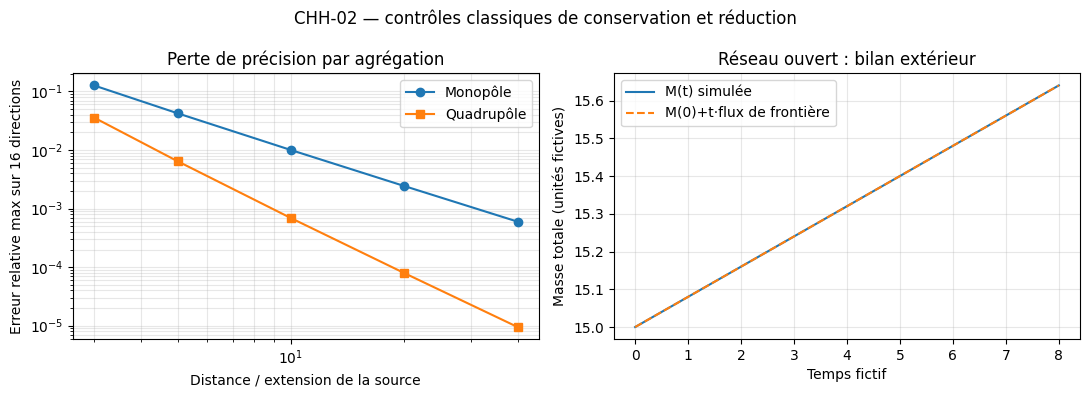

In [8]:
# Graphiques illustratifs ; les courbes ne sont pas des résultats observationnels.
fig,ax=plt.subplots(1,2,figsize=(11,4))
scales=[3,5,10,20,40]
ax[0].loglog(scales,[far_summary[str(k)]['mono_max'] for k in scales],'o-',label='Monopôle')
ax[0].loglog(scales,[far_summary[str(k)]['quad_max'] for k in scales],'s-',label='Quadrupôle')
ax[0].set(xlabel='Distance / extension de la source',ylabel='Erreur relative max sur 16 directions',
          title='Perte de précision par agrégation')
ax[0].grid(True,which='both',alpha=.3);ax[0].legend()
ax[1].plot(t_open,np.sum(ms,axis=1),label='M(t) simulée')
ax[1].plot(t_open,M0+t_open*np.sum(b),'--',label='M(0)+t·flux de frontière')
ax[1].set(xlabel='Temps fictif',ylabel='Masse totale (unités fictives)',title='Réseau ouvert : bilan extérieur')
ax[1].grid(True,alpha=.3);ax[1].legend()
fig.suptitle('CHH-02 — contrôles classiques de conservation et réduction')
fig.tight_layout()
plt.show()

## Niveau 4 — Verdict scientifique et verrou de suite

**PASS local (mécanique et arithmétique classiques) :** les 15 partitions conservent exactement le registre complet de masse, premier moment, impulsion et énergie ; les 15 bilans de frontière sont cohérents ; la dynamique mécanique synthétique conserve son impulsion, son moment cinétique et son énergie à la précision du solveur ; l'erreur de champ externe d'une source monopolaire diminue à grande distance, la correction quadrupolaire classique améliore cette approximation.

**Important :** l'agrégation des quantités **additives** n'implique pas la conservation automatique de l'énergie dans un modèle réduit qui néglige les degrés internes. Les modèles réduits doivent spécifier les variables retenues, les conditions d'application, les erreurs et éventuellement les termes de mémoire.

**BLOQUÉ :** aucune EOM d'interaction et de transport dérivée de `S_cand` ; aucun observable universel d'activité interne ; aucune fréquence indépendante prédite ; aucun étalonnage SI ; aucune validation physique nouvelle ; aucune certification ALMA.

**Prochaine étape :** `GVH_CHH_03_Internal_Dynamics_and_Frequency_FAST` — fréquences de processus distincts, repères temporels communs, modes internes masqués à l'agrégation ; inclure un test de fréquence *held-out* indépendant plutôt que des résonances prescrites présentées comme prédictions. `GCOL-OBS-0.3.2.1.1-PATCH.10H.1` reste séparé, sans ouverture des raies ni retouche de seuils.

**Comparateurs non-GVH :** cours sur les multipôles gravitationnels (https://igpppublic.ucsd.edu/~cathy/Classes/SIO229/grav.pdf) ; revue sur la fermeture des modèles multi-échelles (https://doi.org/10.3934/fods.2024043). Ils ne valident pas GVH.

In [9]:
# Résumé exportable en JSON. Toutes les métriques ont été calculées plus haut.
report={
 'notebook':NAME,
 'classification':'COMPLEMENTARY_NONCANONICAL_CHH_CONSERVATION_AND_AGGREGATION_GATE',
 'local_audit_pass':bool(all(CHECKS.values())),
 'tested_checks':len(CHECKS),
 'checks':CHECKS,
 'four_levels':{
   'GVH':'CHH_COMPOSITION_RULE_CANDIDATE__NOT_DERIVED_FROM_S_CAND',
   'established_physics':'NEWTONIAN_PAIR_CONSERVATION_AND_NETWORK_CONTINUITY',
   'minimal_numeric_test':'FIFTEEN_PARTITIONS_OPEN_NETWORK_ODE_AND_MULTIPOLE_ERRORS',
   'scientific_verdict':'LOCAL_CLASSICAL_QA_PASS__GVH_DYNAMICAL_CLOSURE_AND_INDEPENDENT_PREDICTION_BLOCKED'},
 'conditions':{'synthetic_dimensionless':True,'prescribed_kappa':KAPPA,'tolerance_algebra':ALG_TOL,
               'tolerance_solver':ODE_TOL,'no_derived_SI_scale':True,'no_real_solar_system_fit':True,
               'ALMA_lines_inspected':False,'GVH_USED':False,
               'qa_thresholds_are_not_independent_heldout_validation':True},
 'upstream_sources':UPSTREAM,
 'numeric':{
    'M0':M0,'R0':R0.tolist(),'P0':P0.tolist(),'E0':E0,
    'partitions_count':len(parts),'ledger_max_energy_error':max(abs(z['E_exact']-E0) for z in rows),
    'one_block_reduced_energy_difference':all_one['energy_loss'],
    'four_singletons_reduced_energy_difference':all_four['energy_loss'],
    'open_system_flux_net':float(sum(b)),'open_system_expected_delta_M':float(t_open[-1]*sum(b)),
    'open_system_observed_delta_M':float(sum(ms[-1])-M0),
    'open_system_max_mass_residual':float(np.max(abs(res_open))),
    'mech_momentum_max_error':float(mom_err),'mech_cm_max_error':float(cm_err),
    'mech_angular_momentum_max_error':float(ang_err),'mech_energy_max_error':float(energy_err),
    'source_radius':Rsource,'Q_centered':Q.tolist(),'farfield':far_summary,
    'external_response_difference_same_M_R_P':external_response_difference,
    'microstate_U_d2':float(w2[4]),'microstate_U_d4':float(w4[4])},
 'scientific_locks':{
    'S_cand_coupled_matter_EOM_derived':False,'CHH_effective_dynamics_closed':False,
    'independent_SI_prediction':False,'observational_GVH_validation':False,
    'ALMA_foreground_layer_certified':False,'GVH_used':False},
 'next_step':'GVH_CHH_03_Internal_Dynamics_and_Frequency_FAST'
}
assert report['local_audit_pass']
Path(RESULT_FILE).write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
print('CHH-02 |',len(CHECKS),'audits PASS | verdict:',report['four_levels']['scientific_verdict'])
print('Export:',Path(RESULT_FILE).resolve())

CHH-02 | 56 audits PASS | verdict: LOCAL_CLASSICAL_QA_PASS__GVH_DYNAMICAL_CLOSURE_AND_INDEPENDENT_PREDICTION_BLOCKED
Export: /mnt/data/GVH_CHH_02_Conservation_and_Aggregation_FAST_results.json
